붗꽃(iris) 품종의 종류
<br/>
꽃잎(petal), 꽃받침(sepal)의 폭과 길이로 종을 구분
<br/>
분류 품종 : [setosa, versicolor, virginica]
<br/>
기존 데이터로 학습후 새로운 데이터로 분류하는 방법
<br/>
유사사례 : 지문인식, 홍채인식, 안면인식 등...

In [ ]:
from sklearn.datasets import load_iris

iris = load_iris() # 1. 데이터 호출
# print(iris)
# 2. 데이터 파악 - 어떤 데이터 들이 있는지? 구분할 수 있는 입력 값들은 무엇인지?
print(f'iris 의 키 : {iris.keys()}')
print(f'입력되는 속성의 종류 : {iris.feature_names}')
print(f'맞춰야할 답의 종류 : {iris.target_names}')

iris 의 키 : dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
입력되는 속성의 종류 : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
맞춰야할 답의 종류 : ['setosa' 'versicolor' 'virginica']


In [ ]:
# data: 입력데이터
x = iris.data
# target : 정답 데이터
y = iris.target
print(x[:10])
print(y[:10])

[[5.1 3.5 1.4 0.2]
 [4.9 3.  1.4 0.2]
 [4.7 3.2 1.3 0.2]
 [4.6 3.1 1.5 0.2]
 [5.  3.6 1.4 0.2]
 [5.4 3.9 1.7 0.4]
 [4.6 3.4 1.4 0.3]
 [5.  3.4 1.5 0.2]
 [4.4 2.9 1.4 0.2]
 [4.9 3.1 1.5 0.1]]
[0 0 0 0 0 0 0 0 0 0]


모든 데이터로 학습을 하고 평가를 보게 된다면 과적합(overffiting) 이 일어날 수 있다.
<br/>
이 경우 학습한 패턴에서 조금만 벗어나도 예측을 제대로 하지 못한다.<br/>
그래서 일반적으로 데이터의 70~80% 로 학습을 하고, 나머지로 평가를 한다.

In [ ]:
# 2. 데이터 분할
# random_state : 결과값 재현을 위한 수
# 같은 값을 넣으면 같은 결과를 내보낸다.
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.3, random_state=34, shuffle=True)
print(f'연습용 입력값 형태 : {x_train.shape}')
print(f'시험용 입력값 형태 : {x_test.shape}')
print(f'연습용 정답 형태 : {y_train.shape}')
print(f'시험용 정답 형태 : {y_test.shape}')

연습용 입력값 형태 : (105, 4)
시험용 입력값 형태 : (45, 4)
연습용 정답 형태 : (105,)
시험용 정답 형태 : (45,)


1. x - 입력데이터
2. y - 정답데이터
3. test_size - 데이터 분리시 시험용으로 얼마나 분배할 것인가
4. random_state - 섞을때 seed 값
5. suffle - 분할 전 섞어줄지 여부

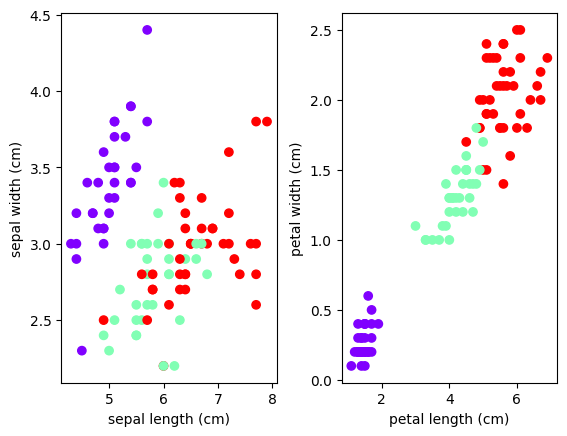

In [ ]:
# 꽃받침(sepal), 꽃잎(petal)  으로 구분하는 분포
import matplotlib.pyplot as plt
import pandas as pd

df = pd.DataFrame(x_train,columns = iris.feature_names)
df
plt.subplot(121)
plt.scatter(df['sepal length (cm)'], df['sepal width (cm)'],c=y_train, cmap=plt.cm.rainbow)
plt.xlabel('sepal length (cm)')
plt.ylabel('sepal width (cm)')

plt.subplot(122)
plt.scatter(df['petal length (cm)'], df['petal width (cm)'],c=y_train, cmap=plt.cm.rainbow)
plt.xlabel('petal length (cm)')
plt.ylabel('petal width (cm)')

plt.subplots_adjust(wspace=0.3)
plt.show()

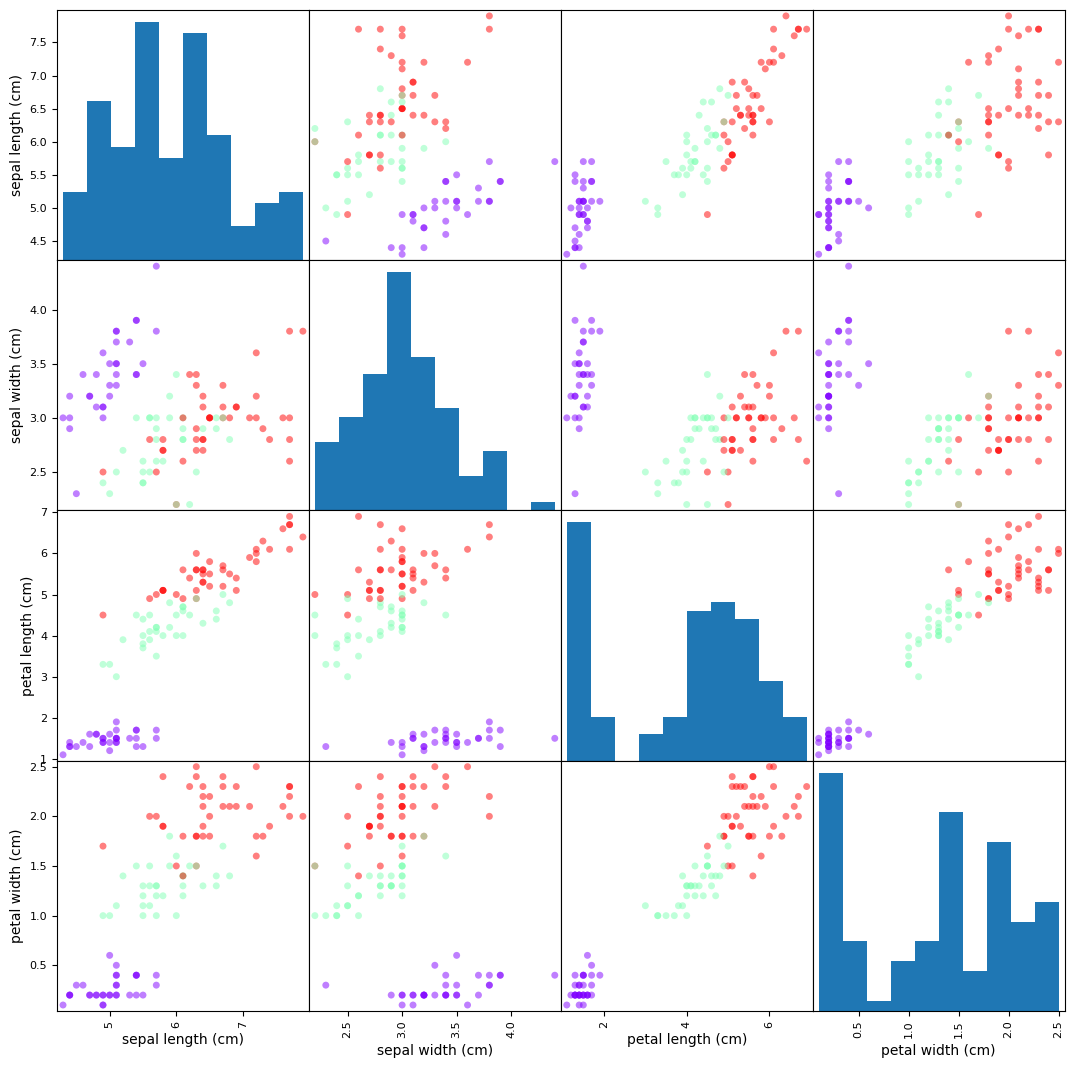

In [ ]:
# 산점도 행렬(scatter matrix) : 주워진 데이터들을 조합하여 산점도를 여러개 만들어 행렬 형태로 보여준다.
pd.plotting.scatter_matrix(df, c=y_train, figsize=(13,13), s=100, cmap=plt.cm.rainbow)
plt.show()

KNN(K Nearst Neighbor)
: 어떤 값으로 부터 근접한 k 값이 어떤 분류인지 구분

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# 1. 사용할 알고리즘 가져오기
class_knn = KNeighborsClassifier(n_neighbors=3) # 인근 값이 몇개정도 있어야 해당 분류로 인정하는가?
# 2. 입력값과 정답을 입력해서 패턴을 추출(fitting)
class_knn.fit(x_train, y_train)

# 3. 예측값 추출
pred_y = class_knn.predict(x_test)
#pred_y

# 4. 정확도 검사
score=class_knn.score(x_test, y_test)
score

0.9777777777777777

In [ ]:
# 실제 활용
# ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)'] 값을 넣으면 종류를 판별해 줍니다.
sample = [[5,5,3,2],[2,4,3,5]]
results =class_knn.predict(sample)
for r in results:
  print(iris.target_names[r])

setosa
virginica


In [ ]:
from joblib import dump
# 학습한 알고리즘을 저장하여 다른곳에서 사용할수도 있다.
root = '/content/drive/MyDrive/운영/MBC/데이터분석_1기/수업/04_ML/Data'
dump(class_knn, f'{root}/knn_iris.joblib')

['/content/drive/MyDrive/운영/MBC/데이터분석_1기/수업/04_ML/Data/knn_iris.joblib']